C:\Users\zzawol\AppData\Local\miniforge3\envs\obspyenv\Lib\site-packages\obspy\io\seg2\seg2.py:365: UserWarning: Many companies use custom defined SEG2 header variables. This might cause basic header information reflected in the single traces' stats to be wrong (e.g. recording delays, first sample number, station code names, ..). Please check the complete list of additional unmapped header fields that gets stored in Trace.stats.seg2 and/or the manual of the source of the SEG2 files for fields that might influence e.g. trace start times.
  warnings.warn(WARNING_HEADER)


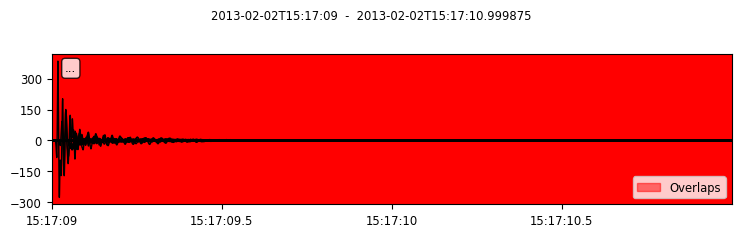

1552388
b'U:\x01\x00\x80\x10\x18\x00\x01\x00\x00\x01\n\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\xe4\x11\x00\x00\xd0\r\x01\x00\xbc\t\x02\x00\xa8\x05\x03\x00\x94\x01\x04\x00\x80\xfd\x04\x00l\xf9\x05\x00X\xf5\x06\x00D\xf1\x07\x000\xed\x08\x00\x1c\xe9\t\x00\x08\xe5\n\x00\xf4\xe0\x0b\x00\xe0\xdc\x0c\x00\xcc\xd8\r\x00\xb8\xd4\x0e\x00\xa4\xd0\x0f\x00\x90\xcc\x10\x00|\xc8\x11\x00h\xc4\x12\x00T\xc0\x13\x00@\xbc\x14\x00,\xb8\x15\x00\x18\xb4\x16\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00'
24 Trace(s) in Stream:

... | 2013-02-02T15:17:09.000000Z - 2013-02-02T15:17:10.999875Z | 8000.0 Hz, 16000 samples
...
(22 other traces)
...
... | 2013-02-02T15:17:09.000000Z - 2013-02-02T15:17:10.999875Z | 8000.0 Hz, 16000 samples



In [7]:
from obspy import read

st = read(r"C:\Users\zzawol\OneDrive - DOI\Documents\MORA25\FluvialSeismology_Analysis\shot_testing\refrapy_test\testt\data\2002.dat")
tr = st[0]

st.plot()

import os

example = r"C:\Users\zzawol\OneDrive - DOI\Documents\MORA25\FluvialSeismology_Analysis\shot_testing\refrapy_test\testt\data\2002.dat"

print(os.path.getsize(example))

with open(example, 'rb') as f:
    print(f.read(200))

print(st)
print(tr.stats)

5406720


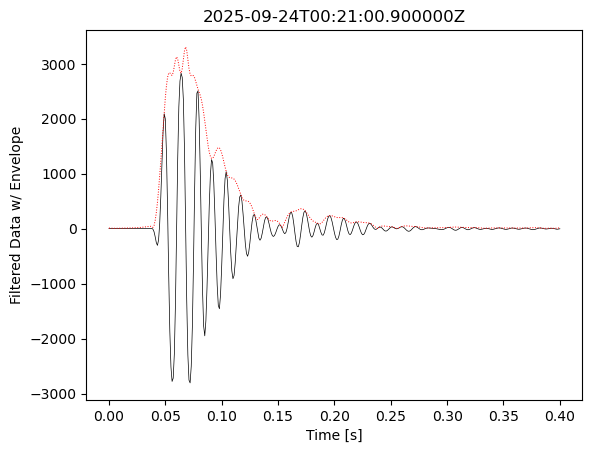

In [17]:
from obspy import read, UTCDateTime
import obspy.signal
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, MaxNLocator, AutoMinorLocator

#start_time = UTCDateTime(2025, 9, 24, 0, 21, 0, 500)
start_time = UTCDateTime("2025-09-24T00:21:00.9")
end_time = UTCDateTime(2025, 9, 24, 0, 21, 14)

#one_impact = UTCDateTime(2025, 9, 24, 0, 21, 2)
one_impact = UTCDateTime("2025-09-24T00:21:01.3")

# st = read(r"D:\calibration_rename\NOC2516\GPZ\ZE.C2516..GPZ_20250924002014.mseed", starttime=start_time, endtime=end_time) # 5 impacts
st = read(r"D:\calibration_rename\NOC2516\GPZ\ZE.C2516..GPZ_20250924002014.mseed", starttime=start_time, endtime=one_impact)

print(os.path.getsize(r"D:\calibration_rename\NOC2516\GPZ\ZE.C2516..GPZ_20250924002014.mseed"))

#st = read(r"D:\2025_MSEED_From_Nodes_rename\NO2516\GPZ\ZE.2516..GPZ_20250924000433.mseed", starttime= start_time, endtime=end_time)
st.merge(method=1)
#st.trim(starttime=start_time, endtime=end_time)
st.trim(starttime=start_time, endtime=one_impact)
tr = st[0]

npts = tr.stats.npts
samprate = tr.stats.sampling_rate

# Filtering the Stream object
st_filt = st.copy()
st_filt.filter('bandpass', freqmin=.1, freqmax=150, corners=4, zerophase=True) #5 corner

# Envelope of filtered data
data_envelope = obspy.signal.filter.envelope(st_filt[0].data)

# The plotting, plain matplotlib
#time = tr.times(reftime=tr.stats.starttime)
t = np.arange(0, npts / samprate, 1 / samprate)
plt.plot(t, st_filt[0].data, 'k', lw=0.5)
plt.plot(t, data_envelope, 'r:', lw=0.7)
plt.title(tr.stats.starttime)
plt.ylabel('Filtered Data w/ Envelope')
plt.xlabel('Time [s]')
#plt.xlim(80, 90)
plt.show()


# time = tr.times(reftime=tr.stats.starttime)
# plt.plot(time, tr.data, lw=0.5)
# plt.show()

C:\Users\zzawol\AppData\Local\miniforge3\envs\obspyenv\Lib\site-packages\obspy\core\util\base.py:26: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


5406720


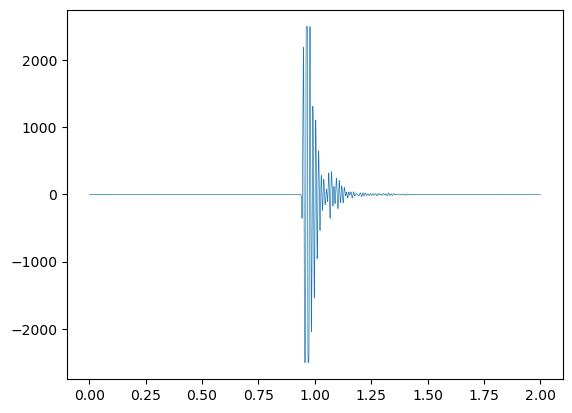

export: 1 Trace(s) in Stream:
SS.05764.SW.GPZ | 2025-09-24T00:21:00.000000Z - 2025-09-24T00:21:00.000000Z | 1000.0 Hz, 1 samples
length: 1
export stats: 1


In [1]:
from obspy import read, UTCDateTime
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, MaxNLocator, AutoMinorLocator

start_time = UTCDateTime(2025, 9, 24, 0, 21)
end_time = UTCDateTime(2025, 9, 24, 0, 21, 14)

one_impact = UTCDateTime(2025, 9, 24, 0, 21, 2)

st = read(r"D:\calibration_rename\NOC2516\GPZ\ZE.C2516..GPZ_20250924002014.mseed", starttime=start_time, endtime=end_time) # 5 impacts
#st = read(r"D:\calibration_rename\NOC2516\GPZ\ZE.C2516..GPZ_20250924002014.mseed", starttime=start_time, endtime=one_impact) # 1 impact

print(os.path.getsize(r"D:\calibration_rename\NOC2516\GPZ\ZE.C2516..GPZ_20250924002014.mseed"))

#st = read(r"D:\2025_MSEED_From_Nodes_rename\NO2516\GPZ\ZE.2516..GPZ_20250924000433.mseed", starttime= start_time, endtime=end_time)
st.merge(method=1)
#st.trim(starttime=start_time, endtime=end_time)
st.trim(starttime=start_time, endtime=end_time)
tr = st[0]

# test_start = tr.stats.starttime
# print(test_start)
# test_end = tr.stats.endtime
# print(test_end)
# #time = tr.times(reftime=test_start)
# time = np.linspace(0, len(tr.data)/tr.stats.sampling_rate, len(tr.data))

# st.plot()
# plt.show()

########

# start = UTCDateTime("2025-09-24T00:20:14")
# end = UTCDateTime("2025-09-24T00:21:14")
#end = start + 60


time = tr.times(reftime=tr.stats.starttime)
plt.plot(time, tr.data, lw=0.5)
# plt.xlim(0, end_time-start_time) # to plot the entered start/end times
#plt.xlim(41, 60)


# fig, ax = plt.subplots(figsize=(12,4))

# ax.plot(time, tr.data, color="black", lw=0.5)

# ax.set_xlim(start, end)#, 30)
# ax.set_xlabel("Time (s)")
# ax.set_ylabel("Amplitude")

# ax.xaxis.set_major_locator(MultipleLocator(5))
# ax.xaxis.set_minor_locator(MultipleLocator(1))

plt.show()

# fig, ax = plt.subplots(figsize=(12, 4))#, dpi=600)
# ax.plot(time, tr.data, color='black', lw=0.5)
# ax.set_title("Waveform")
# ax.set_xlabel("Time (s)")
# ax.set_ylabel("Amplitude")
# ax.xaxis.set_major_locator(MultipleLocator(120))
# ax.xaxis.set_minor_locator(MultipleLocator(30))
# ax.set_xlim(np.min(time), np.max(time))
# #ax.set_ylim(np.min(tr.data)-10, np.max(tr.data)+10)
# plt.show()
# fig.tight_layout()
# plt.close(fig)


export_start = start_time# + 41
export_end = start_time #+ 60

export_st = st.copy()
export_st.trim(starttime=export_start, endtime=export_end)
print("export:",export_st)
print("length:", len(export_st))
print("export stats:", export_st[0].stats.npts)


out_folder = r"C:\Users\zzawol\OneDrive - DOI\Documents\MORA25\FluvialSeismology_Analysis\shot_testing\refrapy_test"
os.makedirs(out_folder, exist_ok=True)
 
for i, tr in enumerate(export_st):
    single = export_st.copy().select(id=tr.id)
    print(single)
    print(f"trace_{i}")
    #single.write(f"trace_{i}.seg2", format="SEG2")


    out_file = os.path.join(out_folder, f"shot_{i:03d}_0.segy")
    print(out_file)

    single.write(out_file, format="SEGY")
    

# shot_st = st.copy()
# shot_st.trim(starttime=export_start,
#              endtime=export_end)

# out_file_2 = os.path.join(out_folder, "shot_001_2.sgy")
# shot_st.write(out_file_2, format="SEGY")

In [14]:
import os
os.getcwd()
from obspy import read

st = read(r"C:\Users\zzawol\OneDrive - DOI\Documents\MORA25\FluvialSeismology_Analysis\shot_testing\refrapy_test\testt\testtt\data\shot_000_0.segy")
print(st)
print(st[0].stats)

1 Trace(s) in Stream:
Seq. No. in line:    0 | 2025-09-24T00:21:00.000000Z - 2025-09-24T00:21:00.000000Z | 1000.0 Hz, 1 samples
         network: 
         station: 
        location: 
         channel: 
       starttime: 2025-09-24T00:21:00.000000Z
         endtime: 2025-09-24T00:21:00.000000Z
   sampling_rate: 1000.0
           delta: 0.001
            npts: 1
           calib: 1.0
         _format: SEGY
            segy: AttribDict({'trace_header': LazyTraceHeaderAttribDict({'unpacked_header': b'\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x01\x03\xe8\x00\x00\x00\x00\x00\x00

In [ ]:
from obspy import read, UTCDateTime
import matplotlib.pyplot as plt

S = read(     )
tr = S[0]

tr.detrend("demean")
tr.detrend("linear")

# tapering prevents 'fake' frequencies from being assumed by FFT --> contaminates filters/spectra
# FFT assumes signal repeats forever when it actually starts and stops
# taper gradually reduces amplitudes near edges, (prevents discontinuous edges) 
# e.g.
# instead of:               |████████|
# it makes it such that:    /████████\    # default is cosine-like

tr.taper(max_percentage=0.05) # tapers first and last 5% of trace
# also maybe try 2%

# filter after taper bc filter assumes smooth edges
tr.filter("bandpass", freqmin=5, freqmax=80, corners=4, zerophase=True) # zero-phase avoids phase delay from filterinng
# corners mean poles, more poles=steeper cutoff but more 'undesired' frequencies (typically 2-6)
# suggested freqmin = 10, freqmax = 80 for first arrival
# to remove poor response from corner freq/river noise (low) and scattering (high)
# but check actual data to see most coherent energy + minimal background noise

# f ~ 1/impact_duration 

# STA/LTA trigger detection: short-term vs long-term avg energy
# STA / LTA = 

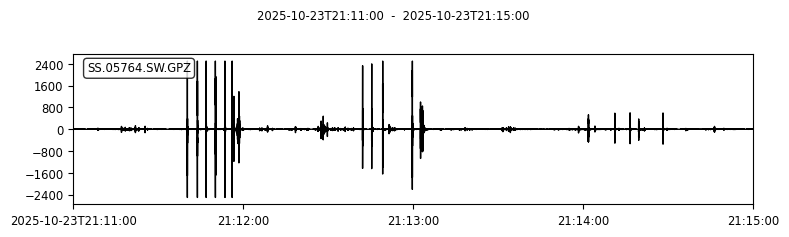

         network: SS
         station: 05764
        location: SW
         channel: GPZ
       starttime: 2025-10-23T21:11:00.000000Z
         endtime: 2025-10-23T21:15:00.000000Z
   sampling_rate: 1000.0
           delta: 0.001
            npts: 240001
           calib: 1.0
         _format: MSEED
           mseed: AttribDict({'dataquality': 'D', 'number_of_records': 239, 'encoding': 'FLOAT32', 'byteorder': '>', 'record_length': 4096, 'filesize': 4079616})
      processing: ['ObsPy 1.4.1: trim(endtime=None::fill_value=None::nearest_sample=True::pad=False::starttime=UTCDateTime(2025, 10, 23, 21, 11))', 'ObsPy 1.4.1: trim(endtime=UTCDateTime(2025, 10, 23, 21, 15)::fill_value=None::nearest_sample=True::pad=False::starttime=None)']

In [17]:
from obspy import read, UTCDateTime
start=UTCDateTime(2025, 10, 23, 21, 11)
end=UTCDateTime(2025, 10, 23, 21, 15)
S = read(r"D:\calibration_rename\NOC2510\GPZ\ZE.C2510..GPZ_20251023211030.mseed", starttime=start, endtime=end)
S.plot()
S[0].stats

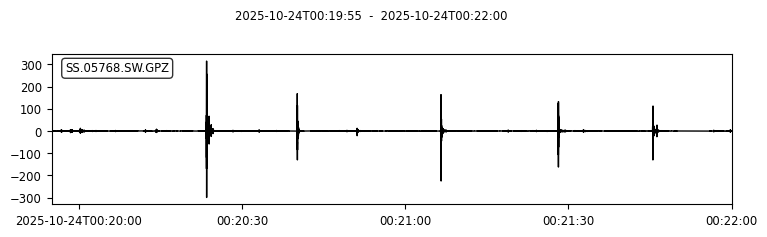

next
Trace range: 2025-10-24T00:00:00.000000Z → 2025-10-25T00:00:00.000000Z
File being read: D:\2025_MSEED_From_Nodes_rename\NO2512\GPZ\ZE.2512..GPZ_20251024000000.mseed
1 Trace(s) in Stream:
SS.05768.SW.GPZ | 2025-10-24T00:00:00.000000Z - 2025-10-25T00:00:00.000000Z | 1000.0 Hz, 86400001 samples
Traces loaded: 1
Sampling rate: 1000.0 Hz
Number of samples: 125001
Plotting and saving raw waveform...


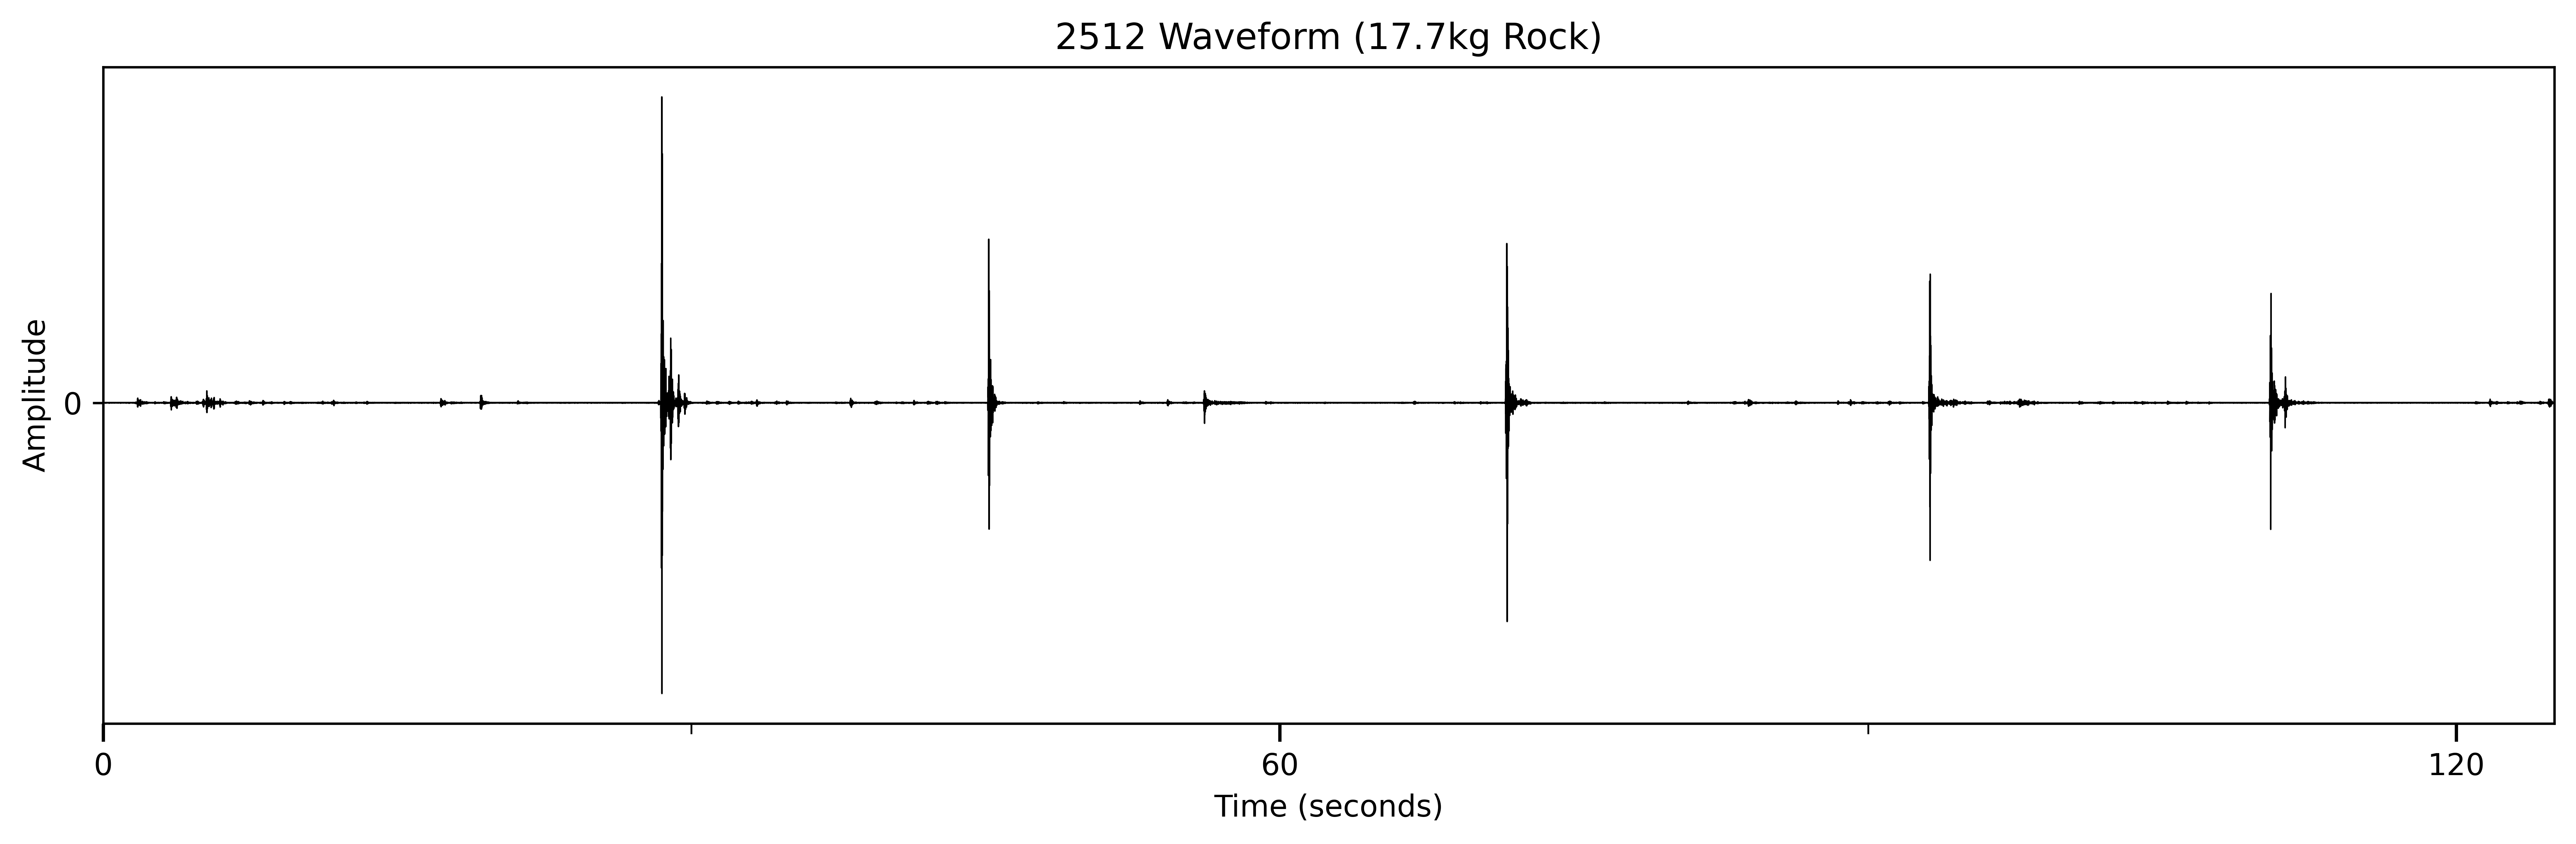

In [8]:
from obspy import read, UTCDateTime
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator

start = UTCDateTime(2025, 10, 24, 00, 19, 55) # N12 rock
end = UTCDateTime(2025, 10, 24, 00, 22)
st = read(r"D:\2025_MSEED_From_Nodes_rename\NO2512\GPZ\ZE.2512..GPZ_20251024000000.mseed", starttime=start, endtime=end)
st.trim(starttime=start, endtime=end)
tr = st[0]

st.plot()

print("next")
node_file = r"D:\2025_MSEED_From_Nodes_rename\NO2512\GPZ\ZE.2512..GPZ_20251024000000.mseed"# r"D:\2025_MSEED_From_Nodes\453005768.*.2025.10.2*.Z.miniseed" #N12

start_time = UTCDateTime(2025, 10, 24, 00, 19, 55) # N12 rock
end_time = UTCDateTime(2025, 10, 24, 00, 22)
#end_time = UTCDateTime(2025, 10, 24, 00, 30, 48)

S = read(node_file)#, starttime=start_time, endtime=end_time)
print("Trace range:", S[0].stats.starttime, "→", S[0].stats.endtime)
print("File being read:", node_file)
print(S)

print("Traces loaded:", len(S))

# merge in case multiple files
S.merge(method=1)

#S.trim(starttime=start_time, endtime=end_time)
tr = S[0].slice(starttime=start_time, endtime=end_time)
#tr = S[0]

print(f"Sampling rate: {tr.stats.sampling_rate} Hz")
print(f"Number of samples: {len(tr.data)}")

# ----------------------------------------------------- raw waveform ----------------------------------------------------------

print("Plotting and saving raw waveform...")

time = np.linspace(0, len(tr.data)/tr.stats.sampling_rate, len(tr.data))

fig, ax = plt.subplots(figsize=(12,4), dpi=600)

ax.plot(time, tr.data, color='black', lw=0.5)

# ticks
ax.xaxis.set_major_locator(MultipleLocator(60)) # labled every 120s
ax.xaxis.set_minor_locator(MultipleLocator(30)) # unlabled every 30s
ax.tick_params(axis='x', which='minor', length=3.5)
ax.tick_params(axis='x', which='major', length=6, width=1.1)
ax.yaxis.set_major_locator(MultipleLocator(500)) # labeled every 500
ax.set_xlim(np.min(time), np.max(time))
ax.set_title("2512 Waveform (17.7kg Rock)")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Amplitude")
fig.tight_layout()

plt.show()


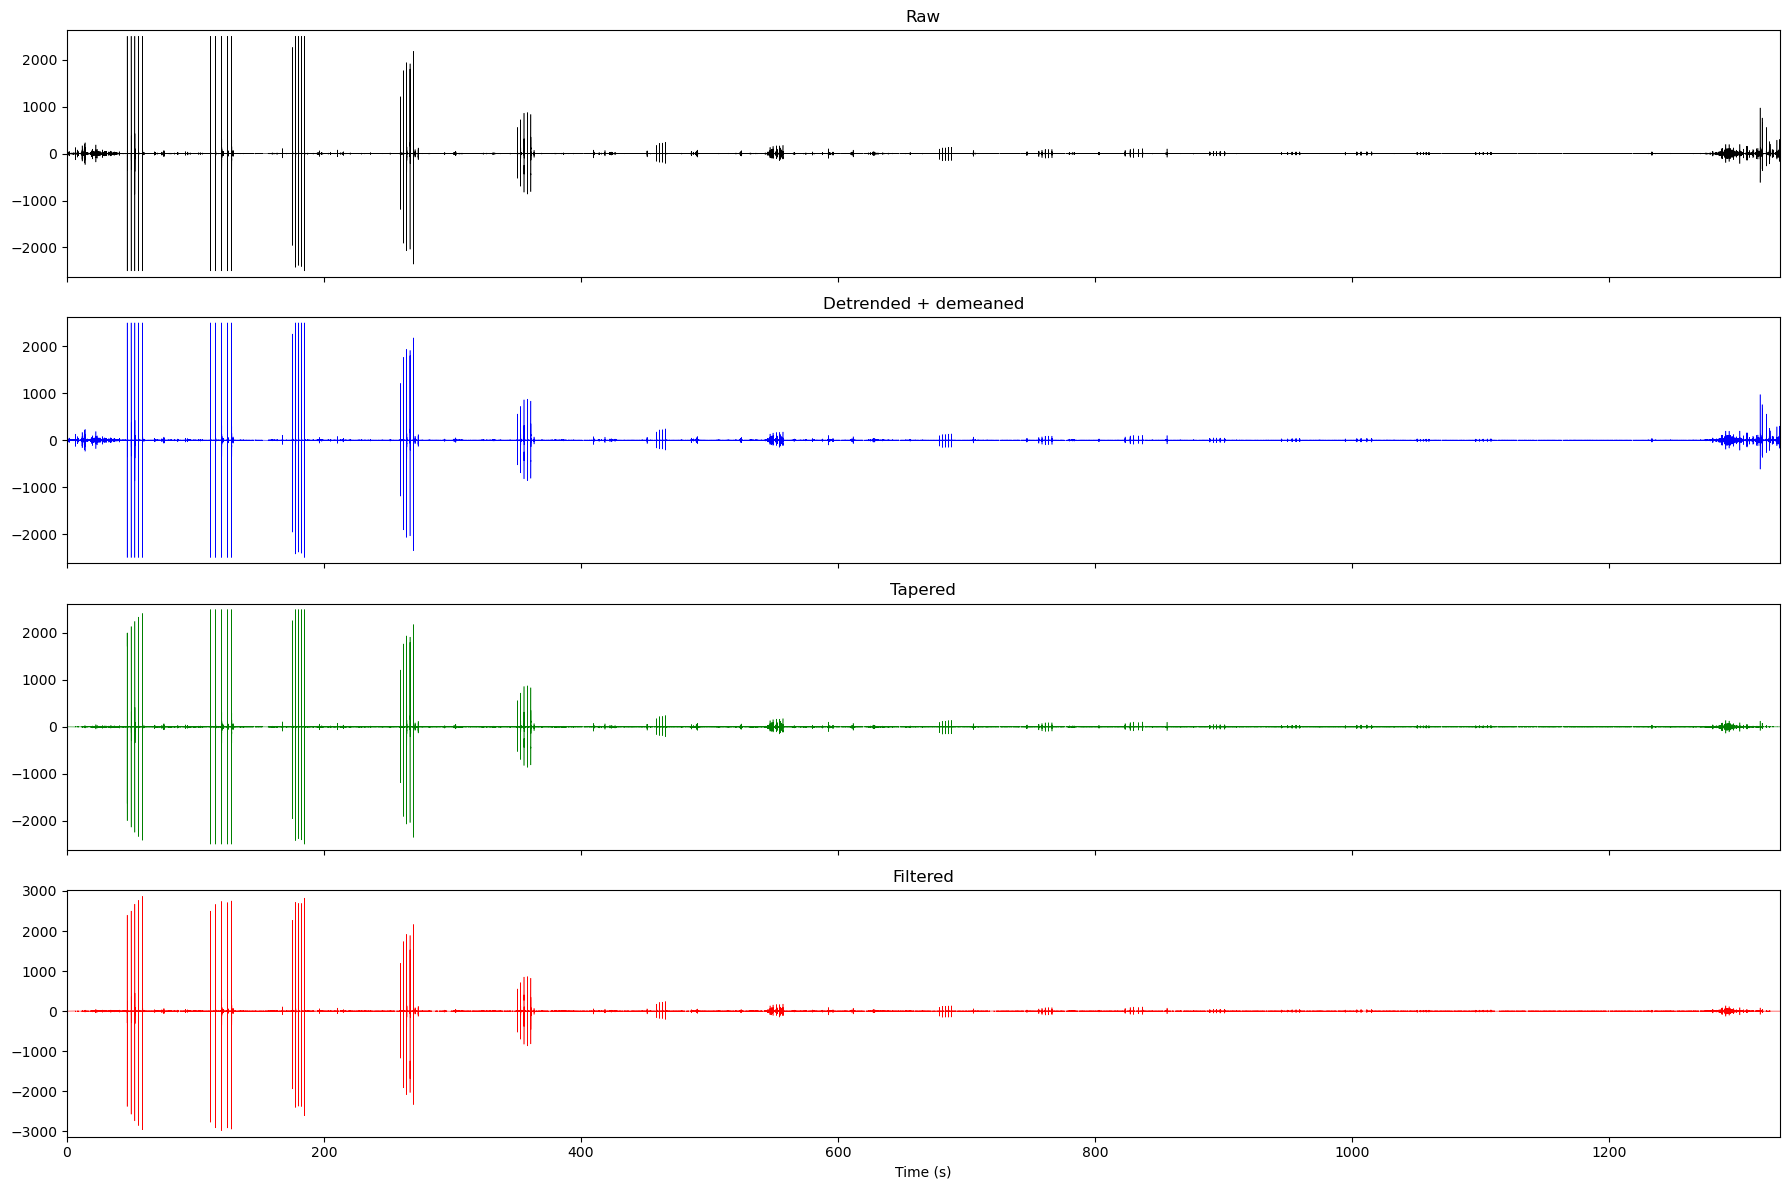

Current Working Directory: C:\Users\zzawol\OneDrive - DOI\Documents\MORA25\FluvialSeismology_Analysis
Saving to: greens_calculating/plots\preprocess_plot.png


In [5]:
from obspy import read, UTCDateTime
import matplotlib.pyplot as plt
import os
import numpy as np

# do as spectra -- exceed over min freq (or amp for raw)
# when y(t)=0 s.t. y>noise => alert: collect time bin for beginning (and end) 

# start = UTCDateTime(2025, 9, 24, 0, 20, 14)
# end = UTCDateTime(2025, 9, 24, 0, 22, 14)

S = read(r"D:\calibration_rename\NOC2516\GPZ\ZE.C2516..GPZ_20250924002014.mseed")#, starttime=start, endtime=end)
tr = S[0]
#sta = ['ZE.C2516..GPZ']
#network, station, location, channel = sta.split('.')

tr_raw = tr.copy()

tr1 = tr.copy()
tr1.detrend("linear")
tr1.detrend("demean")

tr2 = tr1.copy()
tr2.taper(max_percentage=0.05)

tr3 = tr2.copy()
tr3.filter(
    "bandpass",
    freqmin=10,
    freqmax=150,
    corners=4,
    zerophase=True
)

tr4 = tr1.copy()
tr4.filter("bandpass",
           freqmin=1,
           freqmax=150,
           corners=4,zerph

# plot them all together to compare what above does

fig, ax = plt.subplots(4,1, figsize=(18, 12), sharex=True)

ax[0].plot(tr_raw.times(), tr_raw.data, 'k', linewidth=0.4)
ax[0].set_title("Raw")
#ax[0].set_ylim(-5000,5000)
pad = 0.05 * np.max(np.abs(tr_raw.data))
ax[0].set_ylim(np.min(tr_raw.data)-pad, np.max(tr_raw.data)+pad)
ax[0].set_xlim(np.min(tr_raw.times()), np.max(tr_raw.times()))


ax[1].plot(tr1.times(), tr1.data, 'b', linewidth=0.4)
ax[1].set_title("Detrended + demeaned")
ax[1].set_ylim(-5000,5000)
#ax[1].set_xlim(np.min(tr_raw.times()), np.max(tr_raw.times()))

ax[2].plot(tr2.times(), tr2.data, 'g', linewidth=0.4)
ax[2].set_title("Tapered")
ax[2].set_ylim(-5000,5000)
#ax[2].set_xlim(np.min(tr_raw.times()), np.max(tr_raw.times()))

ax[3].plot(tr3.times(), tr3.data, 'r', linewidth=0.4)
ax[3].set_title("Filtered")
ax[3].set_ylim(-5000,5000)
#ax[3].set_xlim(np.min(tr_raw.times()), np.max(tr_raw.times()))

pad = 0.05 * np.max(np.abs(tr1.data))
ax[1].set_ylim(tr1.data.min()-pad, tr1.data.max()+pad)
#ax[1].set_ylim(np.min(tr1.data), np.max(tr1.data))
pad = 0.05 * np.max(np.abs(tr2.data))
ax[2].set_ylim(np.min(tr2.data)-pad, np.max(tr2.data)+pad)
pad = 0.05 * np.max(np.abs(tr3.data))
ax[3].set_ylim(np.min(tr3.data)-pad, np.max(tr3.data)+pad)

plt.xlabel("Time (s)")
# for a in ax:
#     a.set_ylim(-3000, 3000)
plt.tight_layout()
plt.show()

# path = r"C:\Users\zzawol\OneDrive - DOI\Documents\MORA25\FluvialSeismology_Analysis\greens_calculating"
# path_dir = os.path.join(path, "plots")
# os.makedirs(path_dir, exist_ok=True)
# # wave_dir = os.path.join(out_dir, node_type, sta_name, f"{tag}_wave")

# # os.makedirs(wave_dir, exist_ok=True)

# # out_dir = os.path.join(base_out_dir, node_type, station)

# #save_path = os.path.join(spec_dir, f"{station}_{tag}_spectra.png")
# png_dir = (path_dir, "preprocess_plots.png")
# fig.savefig(png_dir, dpi=600, bbox_inches='tight')
# plt.close(fig)


# path = r"C:\Users\zzawol\OneDrive - DOI\Documents\MORA25\FluvialSeismology_Analysis\greens_calculating"

# path_dir = os.path.join(path, "plots")
# os.makedirs(path_dir, exist_ok=True)

# png_dir = os.path.join(path_dir, "preprocess_plots.png")
# print(png_dir)

# fig.savefig(png_dir, dpi=600, bbox_inches='tight')
# plt.close(fig)

import os
print("Current Working Directory:", os.getcwd())
#path = "plots"

#path = r"C:\Users\zzawol\OneDrive - DOI\Documents\MORA25\FluvialSeismology_Analysis"#\greens_calculating"
dirr = "greens_calculating/plots"
os.makedirs(dirr, exist_ok=True)

png_name = "preprocess_plot.png"



png_dir = os.path.join(dirr, png_name)

print("Saving to:", png_dir)

fig.savefig(png_dir, dpi=600, bbox_inches="tight")

plt.close(fig)




# path_dir = os.path.join(dirr, png_name)
# os.makedirs(path_dir, exist_ok=True)
# print("full path:", path_dir)

# # png_dir = os.path.join(path_dir, "preprocess_plots.png")

# # print("Saving to:", png_dir)

# fig.savefig(
#     png_dir,
#     dpi=600,
#     bbox_inches="tight"
# )

# plt.close(fig)


# # try:
# ax[1].set_ylim(np.min(tr1.data), np.max(tr1.data))
# ax[2].set_ylim(np.min(tr2.data), np.max(tr2.data))
# ax[3].set_ylim(np.min(tr3.data), np.max(tr3.data))

# # or
# ax[1].set_ylim(tr1.data.min(), tr1.data.max())
# ax[2].set_ylim(tr2.data.min(), tr2.data.max())
# ax[3].set_ylim(tr3.data.min(), tr3.data.max())

# # extra padding
# pad = 0.05 * np.max(np.abs(tr1.data))
# ax[1].set_ylim(tr1.data.min()-pad, tr1.data.max()+pad)

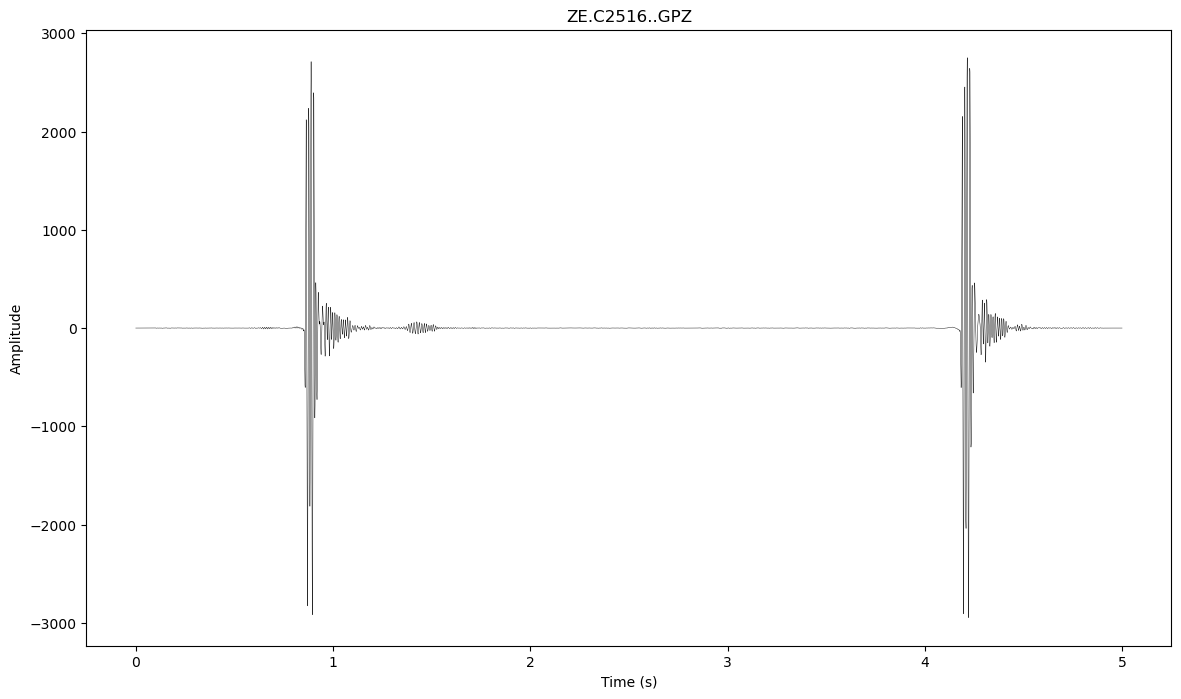

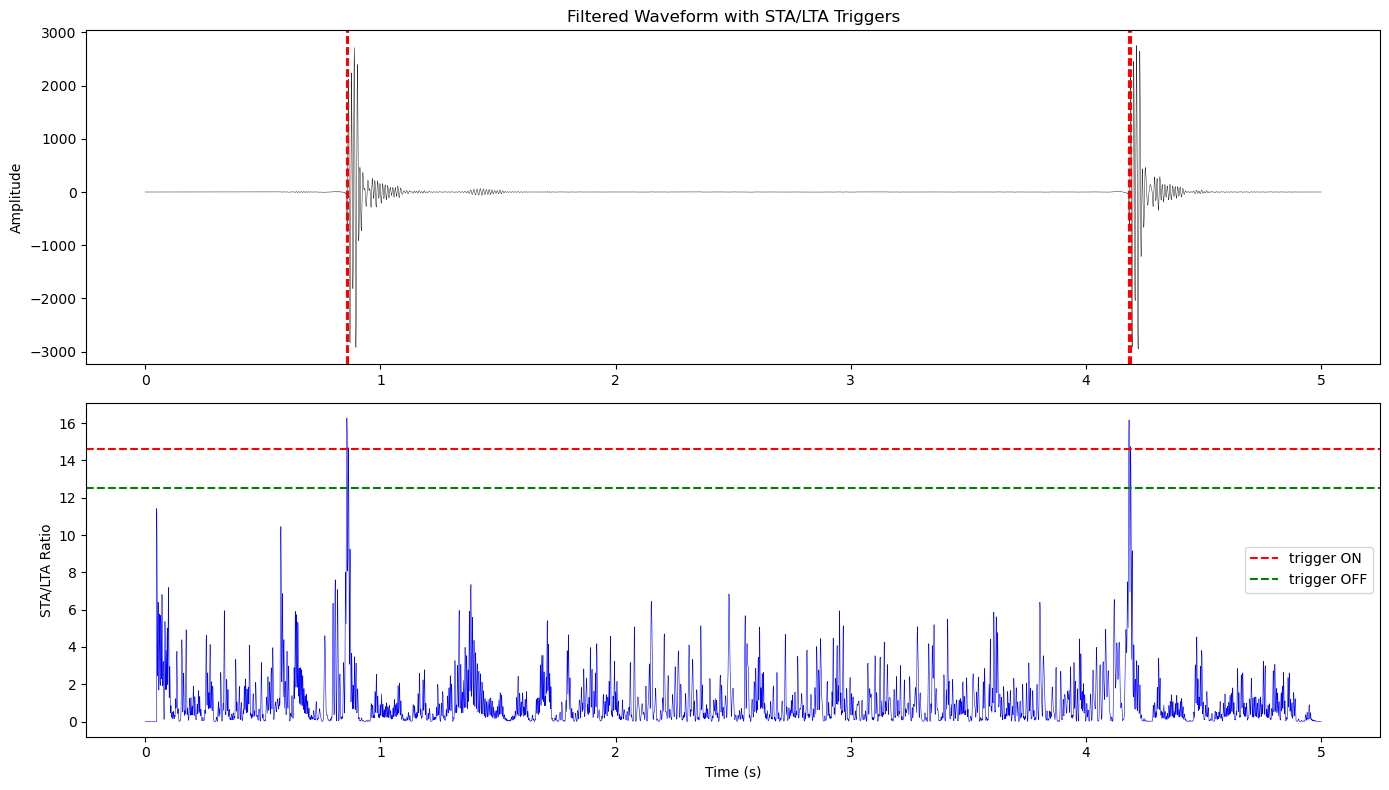

In [52]:
# trying STA/LTA trigger methods

# the idea: has the signal energy suddenly increased relative to background noise?
# trigger rate = short-term-avg / long-term-avg
# LTA = background noise estimate, measures river noise/wind/instrument/ambient
# STA = "instant" signal energy, hammer hits/arrivals
# if STA/LTA = large => signal exceeds background noise => trigger occurs
# but supposedly doesnt directly find first arrivals, but often close enough after filtering
# can later refine with AIC, amnual picking, or stacking

from obspy import read, UTCDateTime
import numpy as np
import matplotlib.pyplot as plt
from obspy.signal.trigger import classic_sta_lta, trigger_onset

# load data
# start = UTCDateTime(2025, 9, 24, 0, 20, 14)
# end = UTCDateTime(2025, 9, 24, 0, 25, 14)

start = UTCDateTime(2025, 9, 24, 0, 22, 18)
end = UTCDateTime(2025, 9, 24, 0, 22, 23)
#end = UTCDateTime(2025, 9, 24, 0, 40)

S = read(r"D:\calibration_rename\NOC2516\GPZ\ZE.C2516..GPZ_20250924002014.mseed", starttime=start, endtime=end)
tr = S[0]

# preprocessing
tr.detrend("linear") # remove linear trend
tr.detrend("demean") # center mean around 0
tr.taper(max_percentage=0.05) # 5% taper (smooth edge artifacts)
tr.filter("bandpass", freqmin=10, freqmax=150, corners=4, zerophase=True)

plt.figure(figsize=(14,8))
plt.plot(tr.times(), tr.data, color='black', linewidth=0.3)
plt.title("ZE.C2516..GPZ")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

# define STA/LTA windows
df = tr.stats.sampling_rate

# try different lengths
sta_len = 0.003 # seconds
lta_len = 0.05 # seconds # typically 5-20x longer than STA

# try 0.02 and 1.0
# trigger when STA >> LTA

# convert sec --> samples
sta_samples = int(sta_len*df)
lta_samples = int(lta_len*df)

cft = classic_sta_lta(tr.data, sta_samples, lta_samples)

# trigger parameters
trigger_on = 14.6 # STA/LTA > 3
trigger_off = 12.5 # so signal decays before trigger resets

triggers = trigger_onset(cft, trigger_on, trigger_off)

# detections
#print("number of triggers:")

trigger_times = []

for on, off in triggers:
    t = (tr.stats.starttime + on/df) # candidate hammer impact times
    trigger_times.append(t)
   # print(len(trigger_time))
    #print("detected triggers:", trigger_time)

# plot
times = tr.times()
plt.figure(figsize=(14,8))
plt.subplot(211)
plt.plot(times, tr.data, color='black', linewidth=0.3)

for on, off in triggers:
    plt.axvline(times[on], color='red', linestyle='--')

plt.ylabel("Amplitude")
plt.title("Filtered Waveform with STA/LTA Triggers")

# STA/LTA characteristic function
# STA/LTA(t) = STA_amplitude / LTA_amplitude at EVERY sample
plt.subplot(212)
plt.plot(times, cft, color='blue', linewidth=0.4)

plt.axhline(trigger_on, color='red', linestyle='--', label="trigger ON")
plt.axhline(trigger_off, color='green', linestyle='--', label="trigger OFF")
plt.ylabel("STA/LTA Ratio")
plt.xlabel("Time (s)")
#plt.ylim(np.min(cft), np.max(cft) +5)
plt.legend()
plt.tight_layout()
plt.show()

# 3rd plot interpretation
# shows at every sample, how much larger is the recent signal energy compared to the background


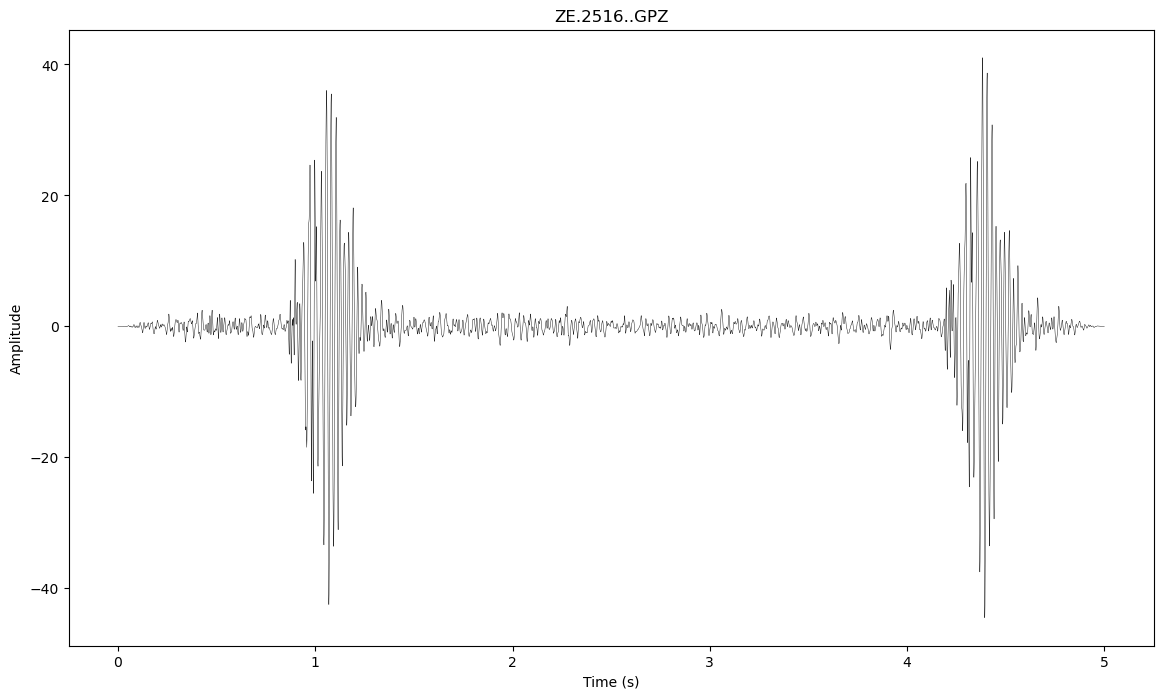

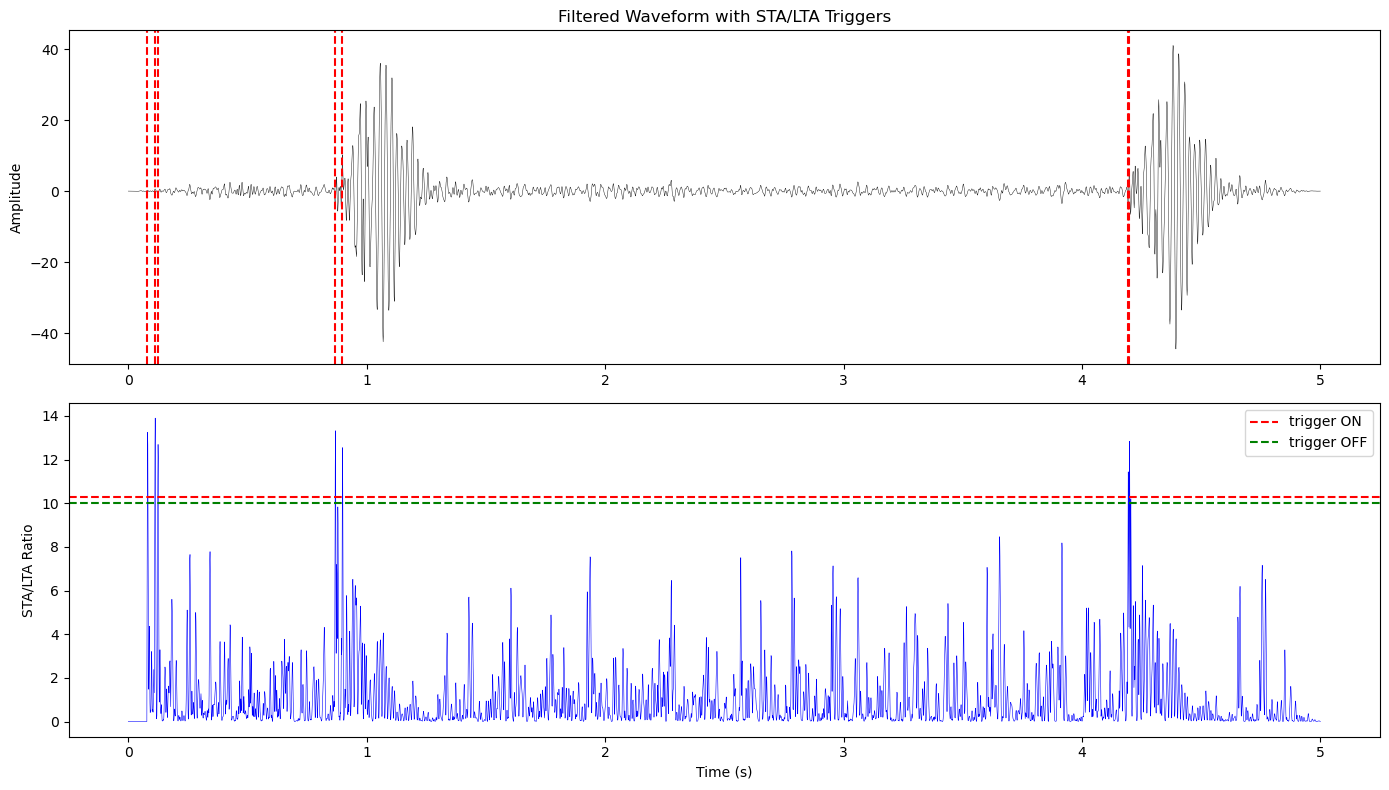

In [14]:
from obspy import read, UTCDateTime
import numpy as np
import matplotlib.pyplot as plt
from obspy.signal.trigger import classic_sta_lta, trigger_onset

# load data
# start = UTCDateTime(2025, 9, 24, 0, 20, 14)
# end = UTCDateTime(2025, 9, 24, 0, 25, 14)

start = UTCDateTime(2025, 9, 24, 0, 22, 18)
end = UTCDateTime(2025, 9, 24, 0, 22, 23)
#end = UTCDateTime(2025, 9, 24, 0, 40)

S = read(r"D:\2025_MSEED_From_Nodes_rename\NO2516\GPZ\ZE.2516..GPZ_20250924000433.mseed", starttime=start, endtime=end)
tr = S[0]

# preprocessing
tr.detrend("linear") # remove linear trend
tr.detrend("demean") # center mean around 0
tr.taper(max_percentage=0.05) # 5% taper (smooth edge artifacts)
tr.filter("bandpass", freqmin=10, freqmax=150, corners=4, zerophase=True)

plt.figure(figsize=(14,8))
plt.plot(tr.times(), tr.data, color='black', linewidth=0.3)
plt.title("ZE.2516..GPZ")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

# define STA/LTA windows
df = tr.stats.sampling_rate

# try different lengths
sta_len = 0.003 # seconds
lta_len = 0.08 # seconds # typically 5-20x longer than STA

# try 0.02 and 1.0
# trigger when STA >> LTA

# convert sec --> samples
sta_samples = int(sta_len*df)
lta_samples = int(lta_len*df)

cft = classic_sta_lta(tr.data, sta_samples, lta_samples)

# trigger parameters
trigger_on = 10.3 # STA/LTA > 3
trigger_off = 10 # so signal decays before trigger resets

triggers = trigger_onset(cft, trigger_on, trigger_off)

# detections
#print("number of triggers:")

trigger_times = []

for on, off in triggers:
    t = (tr.stats.starttime + on/df) # candidate hammer impact times
    trigger_times.append(t)
   # print(len(trigger_time))
    #print("detected triggers:", trigger_time)

# plot
times = tr.times()
plt.figure(figsize=(14,8))
plt.subplot(211)
plt.plot(times, tr.data, color='black', linewidth=0.3)

for on, off in triggers:
    plt.axvline(times[on], color='red', linestyle='--')

plt.ylabel("Amplitude")
plt.title("Filtered Waveform with STA/LTA Triggers")

# STA/LTA characteristic function
# STA/LTA(t) = STA_amplitude / LTA_amplitude at EVERY sample
plt.subplot(212)
plt.plot(times, cft, color='blue', linewidth=0.4)

plt.axhline(trigger_on, color='red', linestyle='--', label="trigger ON")
plt.axhline(trigger_off, color='green', linestyle='--', label="trigger OFF")
plt.ylabel("STA/LTA Ratio")
plt.xlabel("Time (s)")
#plt.ylim(np.min(cft), np.max(cft) +5)
plt.legend()
plt.tight_layout()
plt.show()

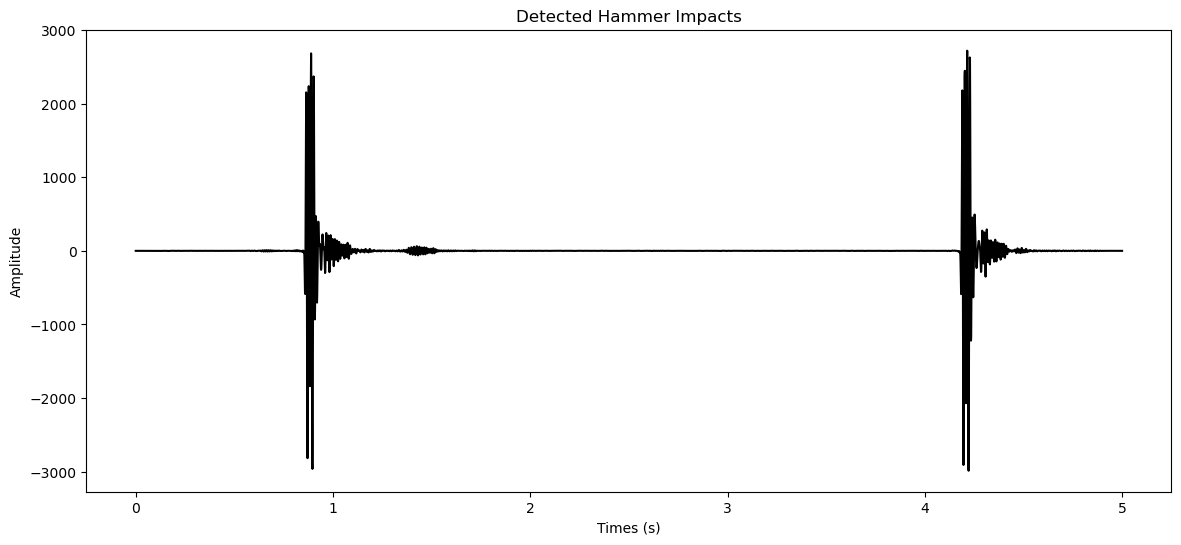

IndexError: list index out of range

In [4]:
# build impact table: 
# distance        impact number
# 2m                    1
# 2m                    2

# windows around impacts
# group repeated impacts
# then stack repeated impacts at each location on transect
# then cross-correlate sstations
# optionally AIC pick first arrivals on stacked traces
# build velocty

import numpy as np
import matplotlib.pyplot as plt
from obspy import read, UTCDateTime
from obspy.signal.trigger import classic_sta_lta, trigger_onset
from scipy.signal import correlate

start = UTCDateTime(2025, 9, 24, 0, 22, 18)
end = UTCDateTime(2025, 9, 24, 0, 22, 23)

S1 = read(r"D:\calibration_rename\NOC2516\GPZ\ZE.C2516..GPZ_20250924002014.mseed", starttime=start, endtime=end)
S2 = read(r"D:\2025_MSEED_From_Nodes_rename\NO2516\GPZ\ZE.2516..GPZ_20250924000433.mseed", starttime=start, endtime=end)


tr1 = S1[0]
tr2 = S2[0]

# preprocess
for tr in [tr1, tr2]:
    # remove mean
    tr.detrend("demean")
    # remove linear lean
    tr.detrend("linear")
    # taper edges (smoothen)
    tr.taper(max_percentage=0.05)
    # bandpass
    tr.filter("bandpass", freqmin=20, freqmax=150, corners=4, zerophase=True)

# calibration node
df = tr1.stats.sampling_rate

sta_len = 0.003 # seconds
lta_len = 0.05 # seconds # typically 5-20x longer than STA
# trigger when STA >> LTA

# convert sec --> samples
sta_samples = int(sta_len*df)
lta_samples = int(lta_len*df)

cft = classic_sta_lta(tr.data, sta_samples, lta_samples)

# trigger parameters
trigger_on = 14.6 # STA/LTA > 14.6
trigger_off = 12.5 # so signal decays before trigger resets

triggers = trigger_onset(cft, trigger_on, trigger_off)

# suppress duplicate triggers (close together ones)
min_spacing = 1.5 # seconds
filtered_triggers = []
last = None

for on, off in triggers:
    t = on/df
    if last is None or (t - last) > min_spacing:
        filtered_triggers.append((on, off))
        last = t
# plot detections
times = tr1.times()
plt.figure(figsize=(14,6))
plt.plot(times, tr1.data, 'k')

for on, off in filtered_triggers:
    plt.axvline(times[on], color='r')
plt.xlabel("Times (s)")
plt.ylabel("Amplitude")
plt.title("Detected Hammer Impacts")
plt.show()

# windows around impacts
# tiny-event centered snippets
# might just end up setting up read start/endtimes and loop through...
windows1 = []
windows2 = []

pre = 0.05
post = 0.20

for on, off in filtered_triggers:
    center = on
    begin = int(center - pre*df)
    stop = int(center + post*df)

    w1 = tr1.data[begin:stop]
    w2 = tr1.data[begin:stop]
    windows1.append(w1)
    windows2.append(w2)
    
# group repeated impacts
# 5 impacts per location on transect
group1 = [windows1[i:i+5] for i in range(0, len(windows1), 5)]
group2 = [windows2[i:i+5] for i in range(0, len(windows2), 5)]
# means accurately ordered trigger

# stack repeated impacts
stacks1 = []
stacks2 = []

for g1, g2 in zip(group1, group2):
    stack1 = np.mean(g1, axis=0)
    stack2 = np.mean(g2, axis=0)
    stacks1.append(stack1)
    
# plot stacked arrivals
t = np.arange(len(stacks1[0])) / df - pre
plt.figure(figsize=(12,6))
plt.plot(t, stacks1[0], label="ZE.C2516..GPZ")
plt.plot(t, stacks2[0], label="ZE.2516..GPZ")
plt.axvline(0, color='k', linestyle='--')
plt.legend()
plt.xlabel("Time Relative to Trigger (s)")
plt.ylabel("Amplitude")
plt.title("Stacked Impacts Arrival")
plt.show()



#### LATER ####

# compute velocity
x1 = 2 # meters
x2 = 28 # meters

def p_velocity(x2, x1, dt): #t2, t1):
    v_p = (x2 - x1)/dt
    return v_p

print(p_velocity(x2, x1, dt))

# AIC picking
# cross-correlation for aligning impacts before stacking, refining differential time, estimating tiny time lags


# AIC workflow:
def aic_picker(trace):
    x = trace.astype(np.float64)
    N = len(x)
    aic = np.zeros(N)

    for k in range(1, N-1):
        var1 = np.var(x[:k])
        var2 = np.var(x[k:])

        if var1 <= 0 or var2 <= 0:
            continue

        aic[k] = (k*np.log(var1) + (N-k-1)*np.log(var2))
    pick = np.argmin(aic) # arrival pick - min indicates onset
    return pick, aic

# example usage
# if stack1 contains stacked hammer arrival
# then pick1, aic1 = aic_picker(stack1) and pick2, aic2 = aic_picker(stack2)
# convert to times: (bc windows begin before trigger time)
# t1 = (pick1/df) - pre
# t2 = (pick/df) - pre
# then velocity: vp = (x2 - x1)/(t2 - t1)

# plot
# plt.figure(figsize=(12,6))

# plt.subplot(211)
# plt.plot(stack1)
# plt.axvline(pick1, color='r')

# plt.title("Stacked waveform")

# plt.subplot(212)
# plt.plot(aic1)
# plt.axvline(pick1, color='r')

# plt.title("AIC function")

# plt.show()


Loading data...
Sampling rate: 1000.0

Preprocessing...

Running STA/LTA...
Raw triggers: 9
Filtered triggers: 9


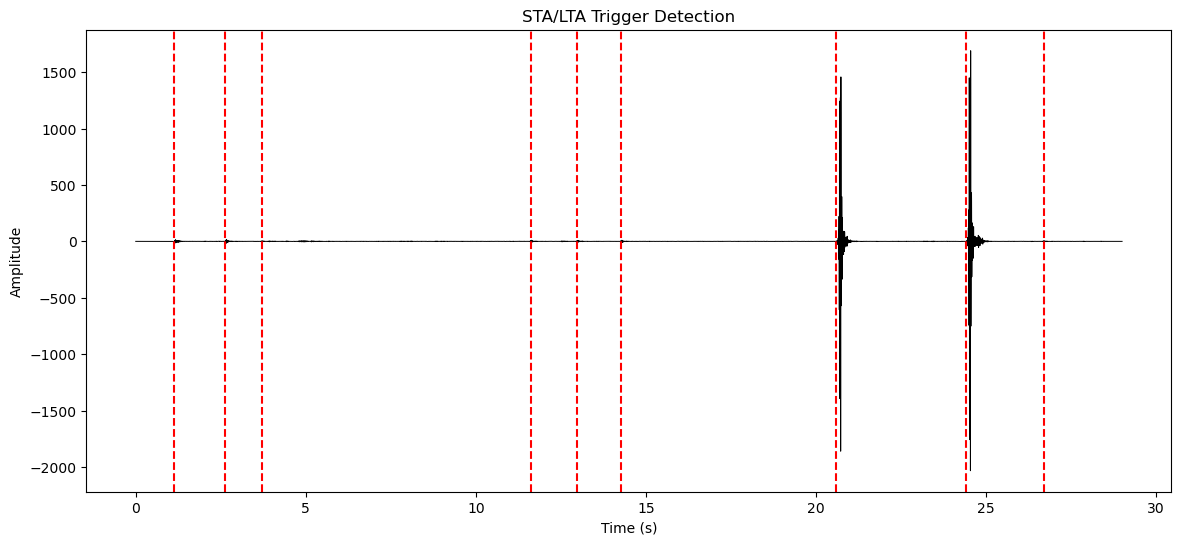


Extracting windows...
Windows extracted: 9

Grouping repeated impacts...
Number of groups: 1

Stacking repeated impacts...
Stacks created: 1


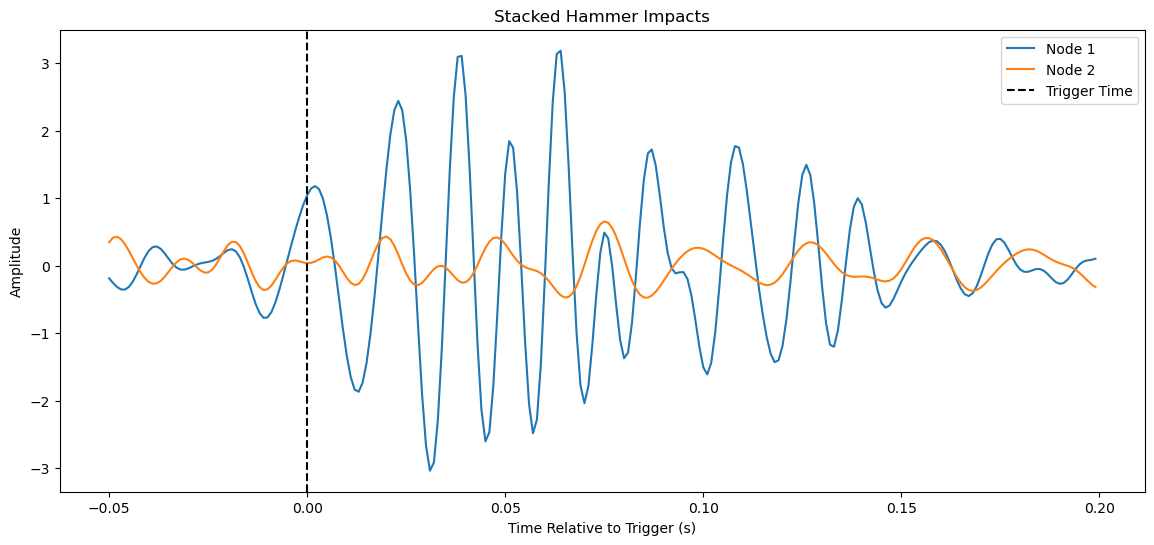


Running AIC picker...

Node 1 arrival: 0.14200000000000002 sec
Node 2 arrival: -0.045000000000000005 sec


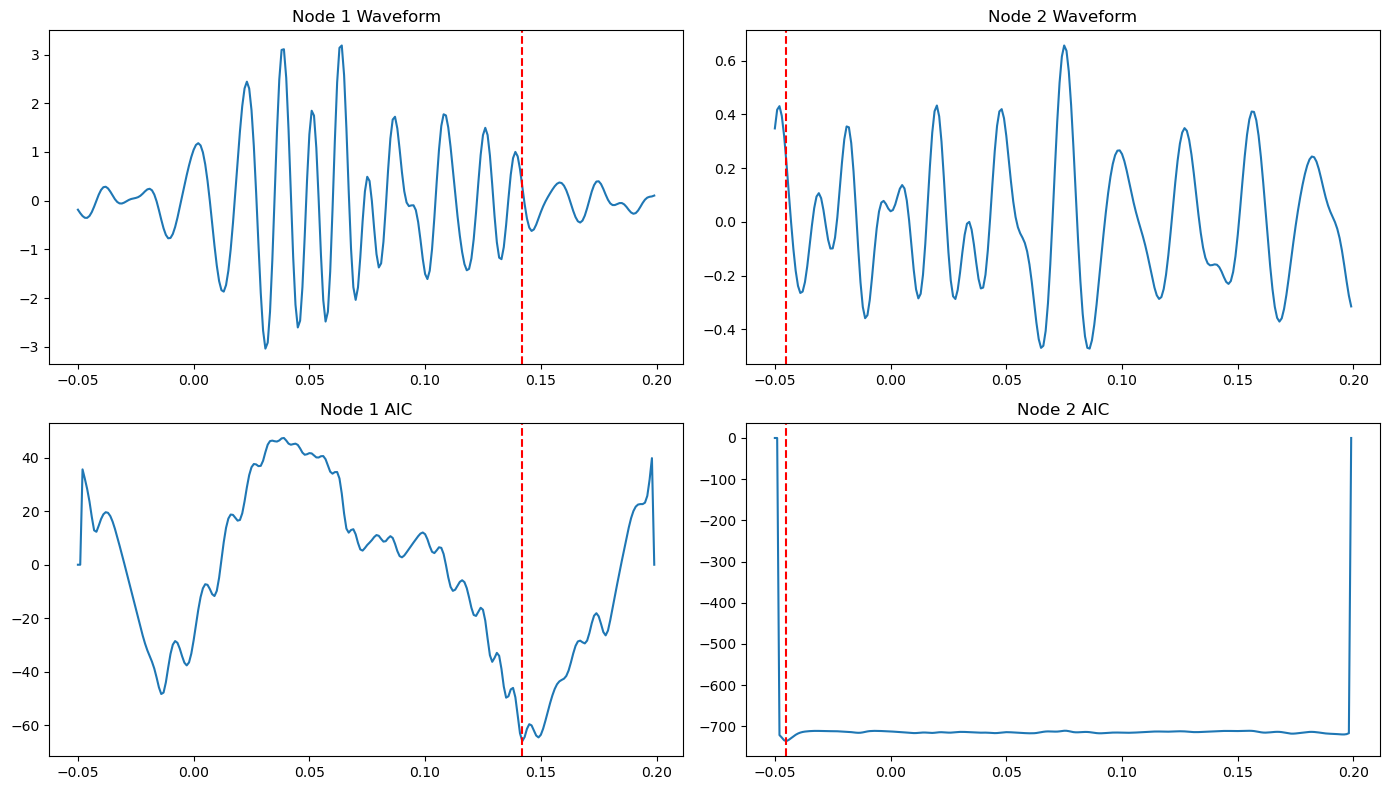


Computing P-wave velocity...

Differential travel time: -0.18700000000000003 sec
Estimated P-wave velocity: -139.03743315508018 m/s


In [11]:
import numpy as np
import matplotlib.pyplot as plt

from obspy import read
from obspy.signal.trigger import classic_sta_lta
from obspy.signal.trigger import trigger_onset

# ============================================================
# USER PARAMETERS
# ============================================================

# FILE1 = "node1.mseed"
# FILE2 = "node2.mseed"

start = UTCDateTime(2025, 9, 24, 0, 21, 45)
end = UTCDateTime(2025, 9, 24, 0, 22, 14)

FILE1 = r"D:\calibration_rename\NOC2516\GPZ\ZE.C2516..GPZ_20250924002014.mseed"#, starttime=start, endtime=end)
FILE2 = r"D:\2025_MSEED_From_Nodes_rename\NO2516\GPZ\ZE.2516..GPZ_20250924000433.mseed"#, starttime=start, endtime=end)

#CHANNEL = "*Z"

# ---------- FILTERING ----------
FREQMIN = 30
FREQMAX = 80

# ---------- STA/LTA ----------
STA = 0.02          # seconds
LTA = 1.0           # seconds

TRIGGER_ON = 12
TRIGGER_OFF = 6

MIN_SPACING = 1.0   # seconds between impacts

# ---------- WINDOW EXTRACTION ----------
PRE = 0.05          # seconds before trigger
POST = 0.20         # seconds after trigger

# ---------- STACKING ----------
GROUP_SIZE = 5      # 5 hammer impacts per location

# ---------- GEOMETRY ----------
NODE_SPACING = 30.0     # meters

SHOT_DISTANCE_NODE1 = 2.0   # meters

# ============================================================
# AIC PICKER
# ============================================================

def aic_picker(trace):

    x = trace.astype(np.float64)

    N = len(x)

    aic = np.zeros(N)

    for k in range(1, N - 1):

        var1 = np.var(x[:k])
        var2 = np.var(x[k:])

        if var1 <= 0 or var2 <= 0:
            continue

        aic[k] = (
            k * np.log(var1)
            +
            (N - k - 1) * np.log(var2)
        )

    pick = np.argmin(aic)

    return pick, aic

# ============================================================
# LOAD DATA
# ============================================================

print("\nLoading data...")

st1 = read(FILE1, starttime=start, endtime=end)
st2 = read(FILE2, starttime=start, endtime=end)

tr1 = st1[0]
tr2 = st2[0]

#tr1 = st1.select(channel=CHANNEL)[0]
#tr2 = st2.select(channel=CHANNEL)[0]

df = tr1.stats.sampling_rate

print("Sampling rate:", df)

# ============================================================
# PREPROCESS
# ============================================================

print("\nPreprocessing...")

for tr in [tr1, tr2]:

    tr.detrend("demean")

    tr.detrend("linear")

    tr.taper(max_percentage=0.05)

    tr.filter(
        "bandpass",
        freqmin=FREQMIN,
        freqmax=FREQMAX,
        corners=4,
        zerophase=True
    )

# ============================================================
# STA/LTA EVENT DETECTION
# ============================================================

print("\nRunning STA/LTA...")

sta_samples = int(STA * df)
lta_samples = int(LTA * df)

cft = classic_sta_lta(
    tr1.data,
    sta_samples,
    lta_samples
)

triggers = trigger_onset(
    cft,
    TRIGGER_ON,
    TRIGGER_OFF
)

print("Raw triggers:", len(triggers))

# ============================================================
# REMOVE DUPLICATE TRIGGERS
# ============================================================

filtered_triggers = []

last_trigger_time = None

for on, off in triggers:

    t = on / df

    if (
        last_trigger_time is None
        or
        (t - last_trigger_time) > MIN_SPACING
    ):

        filtered_triggers.append((on, off))

        last_trigger_time = t

print("Filtered triggers:", len(filtered_triggers))

# ============================================================
# PLOT STA/LTA DETECTIONS
# ============================================================

times = tr1.times()

plt.figure(figsize=(14, 6))

plt.plot(times, tr1.data, 'k', linewidth=0.7)

for on, off in filtered_triggers:

    plt.axvline(
        times[on],
        color='r',
        linestyle='--'
    )

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")

plt.title("STA/LTA Trigger Detection")

plt.show()

# ============================================================
# EXTRACT WINDOWS
# ============================================================

print("\nExtracting windows...")

windows1 = []
windows2 = []

for on, off in filtered_triggers:

    center = on

    start = int(center - PRE * df)
    end = int(center + POST * df)

    # skip bad windows
    if start < 0:
        continue

    if end > len(tr1.data):
        continue

    w1 = tr1.data[start:end]
    w2 = tr2.data[start:end]

    # ensure equal sizes
    if len(w1) != len(w2):
        continue

    windows1.append(w1)
    windows2.append(w2)

print("Windows extracted:", len(windows1))

if len(windows1) == 0:
    raise ValueError("No windows extracted!")

# ============================================================
# GROUP REPEATED SHOTS
# ============================================================

print("\nGrouping repeated impacts...")

groups1 = []
groups2 = []

for i in range(0, len(windows1), GROUP_SIZE):

    g1 = windows1[i:i + GROUP_SIZE]
    g2 = windows2[i:i + GROUP_SIZE]

    if len(g1) == GROUP_SIZE:

        groups1.append(g1)
        groups2.append(g2)

print("Number of groups:", len(groups1))

if len(groups1) == 0:
    raise ValueError("No complete groups found!")

# ============================================================
# STACK REPEATED IMPACTS
# ============================================================

print("\nStacking repeated impacts...")

stacks1 = []
stacks2 = []

for g1, g2 in zip(groups1, groups2):

    stack1 = np.mean(g1, axis=0)
    stack2 = np.mean(g2, axis=0)

    stacks1.append(stack1)
    stacks2.append(stack2)

print("Stacks created:", len(stacks1))

# ============================================================
# PLOT FIRST STACK
# ============================================================

t = np.arange(len(stacks1[0])) / df - PRE

plt.figure(figsize=(14, 6))

plt.plot(
    t,
    stacks1[0],
    label="Node 1"
)

plt.plot(
    t,
    stacks2[0],
    label="Node 2"
)

plt.axvline(
    0,
    color='k',
    linestyle='--',
    label="Trigger Time"
)

plt.xlabel("Time Relative to Trigger (s)")
plt.ylabel("Amplitude")

plt.title("Stacked Hammer Impacts")

plt.legend()

plt.show()

# ============================================================
# AIC PICKING
# ============================================================

print("\nRunning AIC picker...")

pick1, aic1 = aic_picker(stacks1[0])
pick2, aic2 = aic_picker(stacks2[0])

# convert samples to seconds
t1 = (pick1 / df) - PRE
t2 = (pick2 / df) - PRE

print("\nNode 1 arrival:", t1, "sec")
print("Node 2 arrival:", t2, "sec")

# ============================================================
# PLOT AIC PICKS
# ============================================================

fig, ax = plt.subplots(
    2,
    2,
    figsize=(14, 8)
)

# ---------- NODE 1 WAVEFORM ----------
ax[0,0].plot(t, stacks1[0])

ax[0,0].axvline(
    t1,
    color='r',
    linestyle='--'
)

ax[0,0].set_title("Node 1 Waveform")

# ---------- NODE 1 AIC ----------
ax[1,0].plot(t, aic1)

ax[1,0].axvline(
    t1,
    color='r',
    linestyle='--'
)

ax[1,0].set_title("Node 1 AIC")

# ---------- NODE 2 WAVEFORM ----------
ax[0,1].plot(t, stacks2[0])

ax[0,1].axvline(
    t2,
    color='r',
    linestyle='--'
)

ax[0,1].set_title("Node 2 Waveform")

# ---------- NODE 2 AIC ----------
ax[1,1].plot(t, aic2)

ax[1,1].axvline(
    t2,
    color='r',
    linestyle='--'
)

ax[1,1].set_title("Node 2 AIC")

plt.tight_layout()

plt.show()

# ============================================================
# COMPUTE VP
# ============================================================

print("\nComputing P-wave velocity...")

d1 = SHOT_DISTANCE_NODE1

d2 = NODE_SPACING - SHOT_DISTANCE_NODE1

dt = t2 - t1

vp = (d2 - d1) / dt

print("\nDifferential travel time:", dt, "sec")

print("Estimated P-wave velocity:", vp, "m/s")

In [ ]:
import numpy as np

def aic_picker(trace):

    x = trace.astype(np.float64)

    N = len(x)

    aic = np.zeros(N)

    for k in range(1, N-1):

        var1 = np.var(x[:k])
        var2 = np.var(x[k:])

        if var1 <= 0 or var2 <= 0:
            continue

        aic[k] = (
            k * np.log(var1)
            +
            (N-k-1) * np.log(var2)
        )

    pick = np.argmin(aic)

    return pick, aic

Sampling rate: 1000.0 Hz
Samples: 1333001


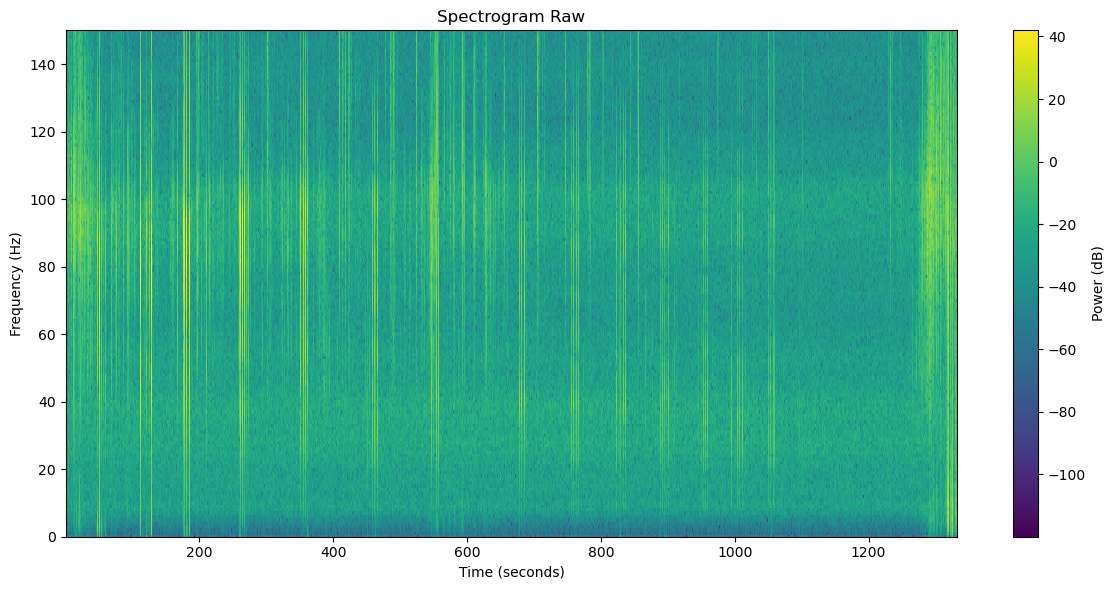

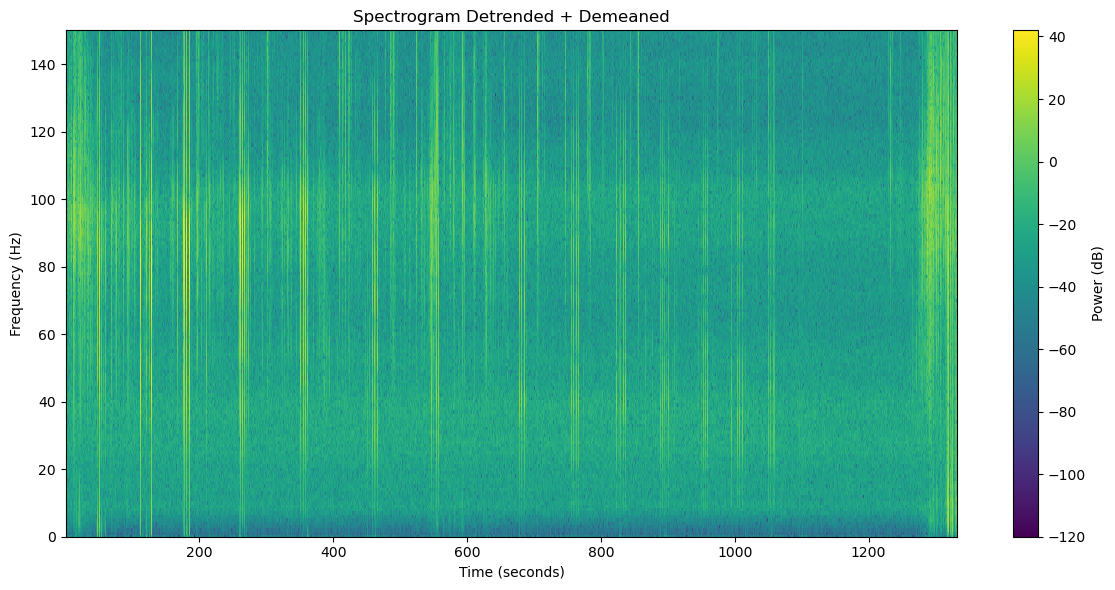

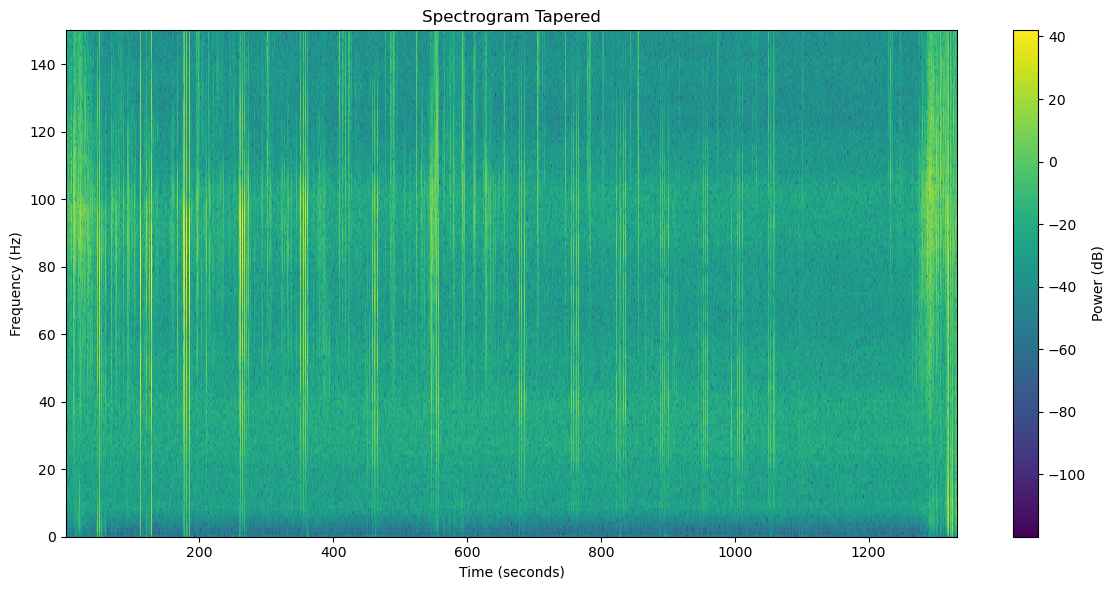

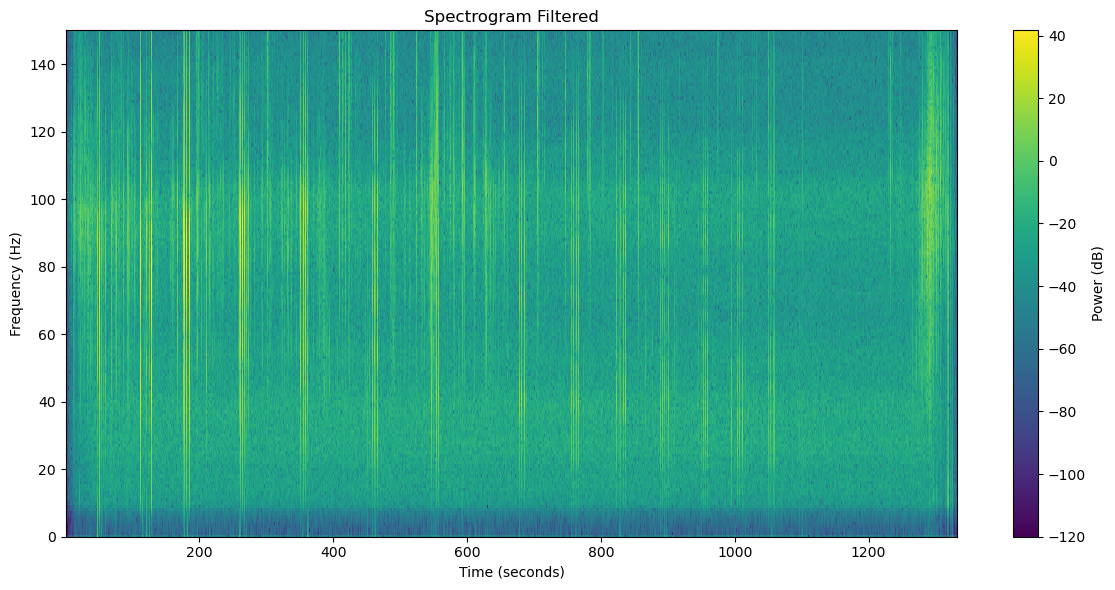

In [9]:
from scipy.signal import spectrogram

fs = tr_raw.stats.sampling_rate
data0 = tr_raw.data
data1 = tr1.data
data2 = tr2.data
data3 = tr3.data

print(f"Sampling rate: {fs} Hz")
print(f"Samples: {len(data0)}")

# -------------------- TIME VECTOR --------------------
time = np.linspace(0, len(data0)/fs, len(data0))

nperseg = int(1 * fs)
noverlap = int(0.5 * fs)

f, t, Sxx = spectrogram(data0, fs=fs, nperseg=nperseg, noverlap=noverlap)

fig, ax = plt.subplots(figsize=(12, 6))

pcm = ax.pcolormesh(t, f, 10*np.log10(Sxx + 1e-12), cmap='viridis')

ax.set_ylim(0, 150)
ax.set_xlim(t.min(), t.max())

ax.set_title("Spectrogram Raw")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Frequency (Hz)")

fig.colorbar(pcm, ax=ax, label="Power (dB)")
fig.tight_layout()
plt.show()

#spec_path = os.path.join(spec_dir, f"{station}_spectra.png")
#fig.savefig(spec_path, dpi=600, bbox_inches='tight')
#plt.close(fig)

################

f, t, Sxx = spectrogram(data1, fs=fs, nperseg=nperseg, noverlap=noverlap)

fig, ax = plt.subplots(figsize=(12, 6))

pcm = ax.pcolormesh(t, f, 10*np.log10(Sxx + 1e-12), cmap='viridis')

ax.set_ylim(0, 150)
ax.set_xlim(t.min(), t.max())

ax.set_title("Spectrogram Detrended + Demeaned")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Frequency (Hz)")

fig.colorbar(pcm, ax=ax, label="Power (dB)")
fig.tight_layout()
plt.show()

########################

f, t, Sxx = spectrogram(data0, fs=fs, nperseg=nperseg, noverlap=noverlap)

fig, ax = plt.subplots(figsize=(12, 6))

pcm = ax.pcolormesh(t, f, 10*np.log10(Sxx + 1e-12), cmap='viridis')

ax.set_ylim(0, 150)
ax.set_xlim(t.min(), t.max())

ax.set_title("Spectrogram Tapered")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Frequency (Hz)")

fig.colorbar(pcm, ax=ax, label="Power (dB)")
fig.tight_layout()
plt.show()

#############################

f, t, Sxx = spectrogram(data3, fs=fs, nperseg=nperseg, noverlap=noverlap)

fig, ax = plt.subplots(figsize=(12, 6))

pcm = ax.pcolormesh(t, f, 10*np.log10(Sxx + 1e-12), cmap='viridis')

ax.set_ylim(0, 150)
ax.set_xlim(t.min(), t.max())

ax.set_title("Spectrogram Filtered")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Frequency (Hz)")

fig.colorbar(pcm, ax=ax, label="Power (dB)")
fig.tight_layout()
plt.show()


In [ ]:
# after preprocessing/filtering
from obspy.signal.filter import envelope
from obspy.signal import peaks
import numpy as np
import matplotlib.pyplot as plt

env = envelope(tr.data)

threshold = np.mean(env) + 5*np.std(env)

peaks, props = find_peaks(env, height=threshold, distance=tr.stats.sampling_rate*1)

impact_times = [tr.stats.starttime + p/tr.stats.sampling_rate
                for p in peaks]
for t in impact_times:
    print(t)

times = tr.times()

plt.figure(figsize=(12,5))
plt.plot(times, tr.data)

# shows red lines for peaks
for p in peaks:
    plt.axvline(times[p], color='r')

plt.show()

In [ ]:
# try AIC picker
# AIC assumes: stationary pre-event noise and distinct change at arrival
# thus must preprocess: linear detrend, taper, bandpass with zerophase=True
# run AIC on very small time windows (100s of ms)

# so run filter cells before this

from obspy.signal.trigger import aic_simple

aic = aic_simple(tr.data) # returns one AIC value per sample

pick_idx = np.argmin(aic) # min AIC = best split point

# convert to time
pick_time = (tr.stats.starttime + pick_idx / tr.stats.sampling_rate)
print(pick_time)

plt.figure(figzise=(12,5))

plt.subplot(211)
plt.plot(tr.times(), tr.data)
plt.axvline(tr.times()[pick_idx], color='r')

plt.subplot(212)
plt.plot(tr.times(), aic)
plt.axvlines(tr.times()[pick_idx], color='r')

plt.show()




In [ ]:
# compare to AR/auto-regressive picker (but designed for earthquake P/S picking)
from obspy.signal.trigger import ar_pick

p_pick, s_pick = ar_pick(tr_z.data, tr_n.data, tr_e.data,
                         df, f1, f2, lta_p, sta_p, lta_s, sta_s, m_p, m_s, l_p, l_s)
# f1, f2 are bandpass frequencies 
# lta_p, sta_p trigger stabilization
# m_p, m_s AR model order (2-8, higher: more sensative, more unstable)
# l_p, l_s variance window lengths (smoothing)
# parameter sensative

In [ ]:
import pandas as pd

data = {
    'station': ['2501', '2502', '2503', '2504','2505', '2506', '2507', '2508', '2509', '2510', '2511', '2512', '2513', '2515', '2516'],
    'calib_station': ['C2501', 'C2502', 'C2503', 'C2504','C2505', 'C2506', 'C2507', 'C2508', 'C2509', 'C2510', 'C2511', 'C2512', 'C2513', 'C2515', 'C2516'],
    'City': ['New York', 'Delhi', 'Pune']
}

'impact_distances': ['2', '4', '6', '8', ...]

# for a single set of impacts (every ONE impact site), i give X time period of that set (e.g. 10s)
# **need function to collect start/arrival and peak**
# function will need end of spike to know to move on to next spike
# this should repeat for each set of impacts along transect

impact_set1 = {'strike1': ['arrival_time', 'peak', 'end_time'],
               'strike2': ['arrival_time', 'peak', 'end_time'],
               'strike3': ['arrival_time', 'peak', 'end_time'],
               'strike4': ['arrival_time', 'peak', 'end_time'],
               'strike5': ['arrival_time', 'peak', 'end_time'],}

# Step 3 Create a DataFrame using DataFrame function
df = pd.DataFrame(data)

# Step 4 Specify the file path to save data
csv_file_path = 'data.csv'

# Step 5 Write the DataFrame to a CSV file using to_csv() function where file path is passed
df.to_csv(csv_file_path, index=False)

print(f'CSV file &quot;{csv_file_path}&quot; has been created successfully.')

In [ ]:
# maybe try using the tau thing since singal (strike) has a more exact location? convert to lat/long --> P wave arrival

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(4,1, sharex=True)

ax[0].plot(tr_raw.times(), tr_raw.data)
ax[0].set_title("Raw")

ax[1].plot(tr1.times(), tr1.data)
ax[1].set_title("Detrended")

ax[2].plot(tr2.times(), tr2.data)
ax[2].set_title("Tapered")

ax[3].plot(tr3.times(), tr3.data)
ax[3].set_title("Filtered")

# also do spectra
tr_raw.spectrogram()
tr3.spectrogram()

tr2.spectrogram 